## 1. Persiapan Data

### Import Libary

In [31]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

Mengimpor library yang diperlukan untuk proses pengolahan data, visualisasi, pembuatan model klasifikasi, dan evaluasi hasil prediksi.

### Extract Dataset

In [2]:
# Ekstraksi dataset
with zipfile.ZipFile('/content/Data UTS.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')

# Melihat isi folder
print(os.listdir('/content/dataset'))

['hasilprediksi_3digitNIMterakhir.csv', 'data_testing.csv', 'data_training.csv']


Mengekstrak file ZIP agar ketiga dataset dapat dibaca dan digunakan dalam proses analisis.

### Membaca Dataset

In [3]:
# Membaca dataset training
df_train = pd.read_csv(
    '/content/dataset/data_training.csv'
)

# Membaca dataset testing
df_test = pd.read_csv(
    '/content/dataset/data_testing.csv'
)

# Membaca template hasil prediksi
df_template = pd.read_csv(
    '/content/dataset/hasilprediksi_3digitNIMterakhir.csv',
    sep=';'
)

# Menampilkan ukuran dataset
print("Ukuran Data Training:", df_train.shape)
print("Ukuran Data Testing:", df_test.shape)
print("Ukuran Template:", df_template.shape)

# Menampilkan beberapa data
display(df_train.head())
display(df_test.head())
display(df_template.head())

Ukuran Data Training: (857, 13)
Ukuran Data Testing: (286, 12)
Ukuran Template: (286, 2)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,222
1,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,1514
2,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,417
3,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,754
4,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,516


,Id,Quality
0,222,NaN
1,1514,NaN
2,417,NaN
3,754,NaN
4,516,NaN


Membaca file data training, data testing, dan template hasil prediksi menggunakan Pandas. Selanjutnya, menampilkan ukuran dan beberapa baris data untuk melihat struktur masing-masing dataset.

### Informasi Dataset

In [4]:
# Informasi data training
print("Informasi Data Training")
df_train.info()

# Informasi data testing
print("\nInformasi Data Testing")
df_test.info()

# Statistik deskriptif
display(df_train.describe())

Informasi Data Training
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   pH                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  
 12  Id                    857 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 87.2 KB

Informasi Data Testing
<class 'pandas.core.frame.Data

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000
mean,8.261960,0.529393,0.267351,2.506184,0.086830,15.782964,45.978413,0.996692,3.313092,0.656709,10.430338,5.653442,813.749125
std,1.701992,0.179162,0.195144,1.293512,0.048721,10.300402,31.692113,0.001901,0.152079,0.167364,1.066971,0.821777,463.807063
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.390000,8.400000,3.000000,0.000000
25%,7.100000,0.395000,0.090000,1.900000,0.070000,7.000000,21.000000,0.995520,3.210000,0.550000,9.500000,5.000000,413.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,14.000000,38.000000,0.996680,3.310000,0.620000,10.200000,6.000000,814.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,63.000000,0.997800,3.400000,0.730000,11.100000,6.000000,1214.000000
max,15.600000,1.580000,1.000000,15.500000,0.611000,68.000000,278.000000,1.003200,4.010000,2.000000,14.000000,8.000000,1597.000000


Melihat informasi dataset, seperti jumlah data, nama kolom, tipe data, dan statistik deskriptif. Tahap ini dilakukan untuk mengetahui karakteristik data sebelum masuk ke proses pengolahan.

### Distribusi Variabel Target

quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64


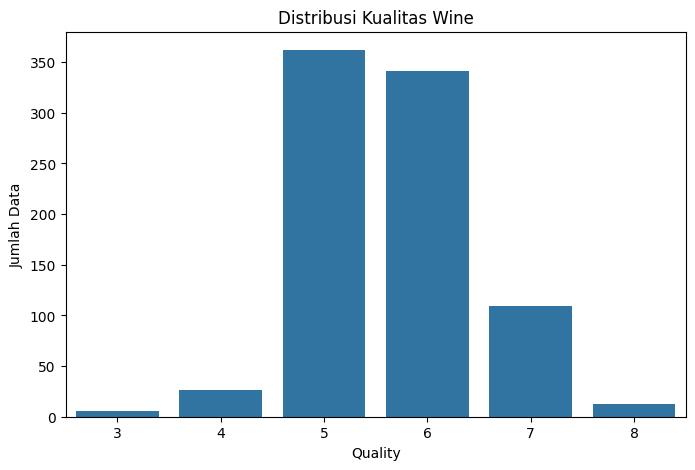

In [6]:
# Menghitung jumlah setiap kategori quality
print(df_train['quality'].value_counts().sort_index())

# Visualisasi distribusi quality
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x='quality'
)

plt.title('Distribusi Kualitas Wine')
plt.xlabel('Quality')
plt.ylabel('Jumlah Data')
plt.show()

Berdasarkan grafik, kualitas wine paling banyak berada pada kategori quality 5 dan 6, sedangkan kategori 3 dan 8 memiliki jumlah data paling sedikit. Hal ini menunjukkan bahwa distribusi kelas belum seimbang karena sebagian besar data terkonsentrasi pada kualitas 5 dan 6. Kondisi tersebut perlu diperhatikan dalam proses pembangunan model klasifikasi.

## 2. Pembersihan Data

### Pemeriksaan Missing Value



In [7]:
# Missing values pada data training
print("Missing Values Data Training:")
print(df_train.isnull().sum())

# Missing values pada data testing
print("\nMissing Values Data Testing:")
print(df_test.isnull().sum())

# Total missing values
print("\nTotal Missing Training:",
      df_train.isnull().sum().sum())

print("Total Missing Testing:",
      df_test.isnull().sum().sum())

Missing Values Data Training:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Missing Values Data Testing:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
Id                      0
dtype: int64

Total Missing Training: 0
Total Missing Testing: 0


Memeriksa apakah terdapat nilai kosong pada dataset training dan testing. Pemeriksaan dilakukan pada setiap kolom untuk memastikan data siap digunakan.

### Penanganan Missing Value

In [10]:
# Membuat imputasi median
imputer = SimpleImputer(strategy='median')

print("Metode penanganan missing values: Median")

Metode penanganan missing values: Median


Menyiapkan metode imputasi menggunakan nilai median untuk menangani data kosong. Metode ini diterapkan melalui Pipeline agar proses preprocessing dapat berjalan bersamaan dengan pelatihan model.

### Pemeriksaan Duplikasi Data

In [8]:
# Pemeriksaan data duplikat
print("Duplikasi Data Training:",
      df_train.duplicated().sum())

print("Duplikasi Data Testing:",
      df_test.duplicated().sum())

Duplikasi Data Training: 0
Duplikasi Data Testing: 0


Memeriksa apakah terdapat baris data yang memiliki nilai sama atau duplikat pada dataset training dan testing.

### Memisahkan Fitur dan Target

In [9]:
# Memisahkan fitur dan target
X = df_train.drop(
    columns=['quality', 'Id']
)

y = df_train['quality']

# Memisahkan fitur data testing
X_test = df_test.drop(
    columns=['Id']
)

# Menyimpan ID data testing
test_id = df_test['Id']

print("Jumlah Fitur:", X.shape[1])
print("Jumlah Data Training:", X.shape[0])
print("Jumlah Data Testing:", X_test.shape[0])

Jumlah Fitur: 11
Jumlah Data Training: 857
Jumlah Data Testing: 286


Memisahkan variabel prediktor dan variabel target. Kolom quality menjadi target yang akan diprediksi, sedangkan kolom Id tidak digunakan dalam pemodelan karena hanya berfungsi sebagai identitas data.

## 3. Pembuatan Model

### Pembagian data

In [32]:
# Membuat 5-Fold Stratified Cross Validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Jumlah Fold:", skf.get_n_splits())
print("Metode: Stratified 5-Fold Cross Validation")

Jumlah Fold: 5
Metode: Stratified 5-Fold Cross Validation


Membagi dataset training menjadi 5 bagian menggunakan Stratified K-Fold Cross Validation. Setiap bagian akan digunakan secara bergantian sebagai data validasi, sedangkan empat bagian lainnya digunakan untuk pelatihan model.

### Pembuatan dan Pengujian Model

In [33]:
# Inisialisasi algoritma
models = {
    'Decision Tree': DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced'
    )
}

# Menyimpan hasil evaluasi
results = {}

for name, model in models.items():

    # Membuat pipeline
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', model)
    ])

    # Melakukan 5-Fold Cross Validation
    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=skf,
        scoring='accuracy'
    )

    # Menghitung rata-rata dan standar deviasi
    mean_accuracy = scores.mean()
    std_accuracy = scores.std()

    # Menyimpan hasil
    results[name] = {
        'model': pipeline,
        'scores': scores,
        'mean_accuracy': mean_accuracy,
        'std_accuracy': std_accuracy
    }

    print(f"\nModel: {name}")

    for i, score in enumerate(scores, 1):
        print(f"Fold {i}: {score:.4f}")

    print(f"Rata-rata Akurasi: {mean_accuracy:.4f}")
    print(f"Standar Deviasi: {std_accuracy:.4f}")


Model: Decision Tree
Fold 1: 0.5640
Fold 2: 0.5814
Fold 3: 0.5673
Fold 4: 0.4912
Fold 5: 0.5263
Rata-rata Akurasi: 0.5460
Standar Deviasi: 0.0329

Model: Random Forest
Fold 1: 0.5930
Fold 2: 0.6570
Fold 3: 0.6374
Fold 4: 0.6667
Fold 5: 0.6784
Rata-rata Akurasi: 0.6465
Standar Deviasi: 0.0299


Melakukan pengujian terhadap Decision Tree dan Random Forest menggunakan 5-Fold Cross Validation. Setiap model diuji sebanyak lima kali, kemudian nilai akurasi dari seluruh fold dihitung rata-ratanya untuk mengetahui performa masing-masing model.

### Perbandingan Performa model

In [34]:
# Membuat tabel perbandingan
comparison = pd.DataFrame([
    {
        'Model': name,
        'Rata-rata Accuracy': result['mean_accuracy'],
        'Standar Deviasi': result['std_accuracy']
    }
    for name, result in results.items()
])

comparison = comparison.sort_values(
    by='Rata-rata Accuracy',
    ascending=False
)

display(comparison)

,Model,Rata-rata Accuracy,Standar Deviasi
1,Random Forest,0.646491,0.029912
0,Decision Tree,0.546029,0.032907


Membandingkan rata-rata akurasi dan standar deviasi dari kedua model. Model dengan rata-rata akurasi tertinggi dipilih sebagai model terbaik, sedangkan standar deviasi digunakan untuk melihat variasi hasil akurasi antar-fold.

### Pemilihan Model Terbaik

In [36]:
# Memilih model berdasarkan rata-rata akurasi tertinggi
best_model_name = max(
    results,
    key=lambda x: results[x]['mean_accuracy']
)

best_model = results[best_model_name]['model']

print("Model Terbaik:", best_model_name)

print(
    "Rata-rata Akurasi:",
    results[best_model_name]['mean_accuracy']
)

print(
    "Standar Deviasi:",
    results[best_model_name]['std_accuracy']
)

Model Terbaik: Random Forest
Rata-rata Akurasi: 0.6464912280701753
Standar Deviasi: 0.02991241579914318


Menentukan model terbaik berdasarkan nilai rata-rata akurasi tertinggi dari lima percobaan. Model terpilih selanjutnya digunakan untuk evaluasi lebih lanjut dan prediksi data testing. Model terbaik yang diperoleh yaitu Random Forest dengan rata-rata akurasi 0.6464912280701753 dan Standar devisiasi 0.02991241579914318

### Evaluasi Model

Model Terbaik: Random Forest
Accuracy: 0.646441073512252
Accuracy (%): 64.6441073512252

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.00      0.00      0.00        26
           5       0.69      0.76      0.72       362
           6       0.60      0.67      0.64       341
           7       0.64      0.45      0.53       109
           8       1.00      0.15      0.27        13

    accuracy                           0.65       857
   macro avg       0.49      0.34      0.36       857
weighted avg       0.63      0.65      0.63       857



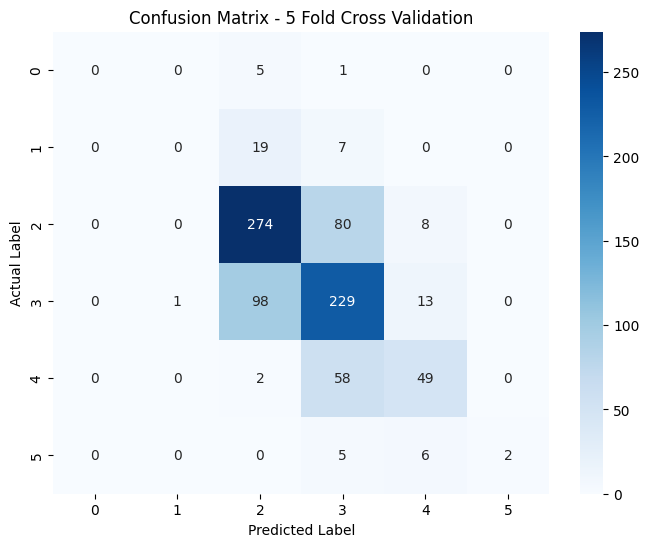

In [37]:
# Prediksi menggunakan 5-Fold Cross Validation
y_pred = cross_val_predict(
    best_model,
    X,
    y,
    cv=skf
)

# Menghitung akurasi
accuracy = accuracy_score(y, y_pred)

print("Model Terbaik:", best_model_name)
print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

# Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y,
        y_pred,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(y, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix - 5 Fold Cross Validation')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

Mengevaluasi model terbaik menggunakan hasil prediksi dari lima fold. Evaluasi dilakukan menggunakan accuracy, precision, recall, F1-score, dan confusion matrix untuk mengetahui kemampuan model dalam mengklasifikasikan setiap kategori kualitas wine. Berdasarkan confusion matrix, model mampu mengklasifikasikan sebagian besar data dengan benar, terutama pada kategori quality 5 dan 6. Namun, masih terdapat kesalahan prediksi, khususnya antara kategori quality 5 dan 6. Dari total 857 data, sebanyak 554 data berhasil diklasifikasikan dengan tepat, sehingga menghasilkan akurasi sebesar 64,64%. Hal ini menunjukkan bahwa model sudah cukup mampu mengenali kualitas wine, tetapi masih mengalami kesulitan dalam membedakan beberapa kategori yang berdekatan.

### Menyimpan Model

In [38]:
# Melatih model terbaik menggunakan seluruh data training
best_model.fit(X, y)

# Menyimpan model
joblib.dump(
    best_model,
    '/content/model_wine_quality.pkl'
)

print("Model terbaik berhasil dilatih dan disimpan!")

Model terbaik berhasil dilatih dan disimpan!


Melatih kembali model terbaik menggunakan seluruh 857 data training. Setelah proses pelatihan selesai, model disimpan dalam format .pkl menggunakan Joblib agar dapat digunakan untuk memprediksi data testing.

## 4. Prediksi Data Uji

### Melatih Model dengan 5-Fold Cross Validation

In [39]:
from sklearn.base import clone

# Menyiapkan penyimpanan model
fold_models = []

# Melatih model pada setiap fold
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):

    # Membagi data berdasarkan fold
    X_fold_train = X.iloc[train_idx]
    y_fold_train = y.iloc[train_idx]

    # Membuat salinan model terbaik
    fold_model = clone(best_model)

    # Melatih model
    fold_model.fit(X_fold_train, y_fold_train)

    # Menyimpan model
    fold_models.append(fold_model)

    print(f"Model Fold {fold} berhasil dilatih!")

print("\nTotal model yang dilatih:", len(fold_models))

Model Fold 1 berhasil dilatih!
Model Fold 2 berhasil dilatih!
Model Fold 3 berhasil dilatih!
Model Fold 4 berhasil dilatih!
Model Fold 5 berhasil dilatih!

Total model yang dilatih: 5


Melatih model terbaik sebanyak lima kali menggunakan pembagian data yang berbeda pada setiap fold. Setiap model dilatih menggunakan empat bagian data training dan satu bagian lainnya digunakan sebagai validasi. Kelima model kemudian disimpan untuk digunakan dalam proses prediksi data testing.

### Prediksi Data Testing pada Setiap Fold

In [42]:
# Menyimpan hasil prediksi setiap fold
predictions = []

for i, model in enumerate(fold_models, 1):

    # Melakukan prediksi data testing
    y_pred_test = model.predict(X_test)

    # Menyimpan hasil prediksi
    predictions.append(y_pred_test)

    print(f"Prediksi Fold {i} selesai!")

# Menggabungkan hasil prediksi
predictions = np.array(predictions)

# Membuat tabel hasil prediksi setiap fold
df_perbandingan = pd.DataFrame(
    predictions.T,
    columns=[
        'Fold 1',
        'Fold 2',
        'Fold 3',
        'Fold 4',
        'Fold 5'
    ]
)

# Menambahkan ID
df_perbandingan.insert(0, 'Id', test_id.values)

# Menampilkan hasil
display(df_perbandingan.head(20))

print("\nJumlah data:", len(df_perbandingan))

Prediksi Fold 1 selesai!
Prediksi Fold 2 selesai!
Prediksi Fold 3 selesai!
Prediksi Fold 4 selesai!
Prediksi Fold 5 selesai!


,Id,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
0,222,5,5,5,5,5
1,1514,6,6,5,6,6
2,417,5,5,5,5,5
3,754,5,5,5,5,5
4,516,6,5,5,5,5
5,1120,6,6,6,6,6
6,180,5,5,5,5,5
7,82,5,5,5,5,5
8,632,5,6,5,6,5
9,592,5,5,5,5,5



Jumlah data: 286


Melakukan prediksi terhadap seluruh data testing menggunakan lima model hasil Cross Validation. Hasil prediksi setiap model ditampilkan dalam tabel untuk melihat perbedaan klasifikasi pada masing-masing fold

### Menentukan Hasil Prediksi dengan Majority Voting

In [43]:
from scipy.stats import mode

# Menentukan prediksi berdasarkan voting mayoritas
y_test_pred = mode(
    predictions,
    axis=0,
    keepdims=False
).mode

# Menampilkan hasil prediksi
df_prediksi = pd.DataFrame({
    'Id': test_id,
    'Quality': y_test_pred
})

display(df_prediksi.head(10))

print("Total data diprediksi:", len(df_prediksi))

,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,5
5,1120,6
6,180,5
7,82,5
8,632,5
9,592,5


Total data diprediksi: 286


Menggabungkan hasil prediksi dari kelima model menggunakan metode majority voting. Kategori quality yang paling banyak dipilih oleh kelima model akan menjadi hasil prediksi akhir untuk setiap data testing.

### Memasukkan Hasil ke Template

In [44]:
# Memastikan ID sesuai dengan dataset testing
assert df_template['Id'].equals(df_test['Id']), \
    "Urutan ID tidak sesuai!"

# Memasukkan hasil prediksi
df_template['Quality'] = y_test_pred

# Menampilkan hasil
display(df_template.head(10))

print("Jumlah data:", len(df_template))

,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,5
5,1120,6
6,180,5
7,82,5
8,632,5
9,592,5


Jumlah data: 286


Memasukkan hasil prediksi akhir ke dalam template yang telah disediakan. Pemeriksaan ID dilakukan untuk memastikan hasil prediksi sesuai dengan urutan data testing.

### Menyimpan Hasil Prediksi

In [45]:
# Menyimpan hasil prediksi
df_template.to_csv(
    '/content/hasil_prediksi.csv',
    sep=';',
    index=False
)

print("File hasil_prediksi.csv berhasil disimpan!")

File hasil_prediksi.csv berhasil disimpan!


Menyimpan hasil prediksi ke dalam file CSV dengan nama hasil_prediksi.csv. File tersebut berisi ID dan kategori quality hasil klasifikasi.

### Menyimpan Model

In [47]:
# Menyimpan kelima model
joblib.dump(
    fold_models,
    '/content/model_wine_quality_5fold.pkl'
)

print("Kelima model berhasil disimpan!")

Kelima model berhasil disimpan!


### Download File

In [48]:
from google.colab import files

# Download hasil prediksi
files.download('/content/hasil_prediksi.csv')

# Download model
files.download('/content/model_wine_quality.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>